In [1]:
#Uplode

from google.colab import files

uplode = files.upload()

Saving StudentsPerformance (1).csv to StudentsPerformance (1).csv


missing values,duplicate handling,data types,standartizing formats,summary statistics,outlier detection

In [2]:
#Import

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
import pandas as pd
df = pd.read_csv("StudentsPerformance (1).csv")


data cleaning-missing values,duplicates and data type

In [4]:
#data cleaning-missing values,duplicates and data type
df.head()

,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score
0,female,group B,bachelor's degree,standard,none,72,72,74
1,female,group C,some college,standard,completed,69,90,88
2,female,group B,master's degree,standard,none,90,95,93
3,male,group A,associate's degree,free/reduced,none,47,57,44
4,male,group C,some college,standard,none,76,78,75


In [5]:
df.tail()

,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score
995,female,group E,master's degree,standard,completed,88,99,95
996,male,group C,high school,free/reduced,none,62,55,55
997,female,group C,high school,free/reduced,completed,59,71,65
998,female,group D,some college,standard,completed,68,78,77
999,female,group D,some college,free/reduced,none,77,86,86


In [6]:
df.shape

(1000, 8)

In [7]:
df.columns

Index(['gender', 'race/ethnicity', 'parental level of education', 'lunch',
       'test preparation course', 'math score', 'reading score',
       'writing score'],
      dtype='object')

In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 8 columns):
 #   Column                       Non-Null Count  Dtype 
---  ------                       --------------  ----- 
 0   gender                       1000 non-null   object
 1   race/ethnicity               1000 non-null   object
 2   parental level of education  1000 non-null   object
 3   lunch                        1000 non-null   object
 4   test preparation course      1000 non-null   object
 5   math score                   1000 non-null   int64 
 6   reading score                1000 non-null   int64 
 7   writing score                1000 non-null   int64 
dtypes: int64(3), object(5)
memory usage: 62.6+ KB


In [9]:
df.describe()

,math score,reading score,writing score
count,1000.00000,1000.000000,1000.000000
mean,66.08900,69.169000,68.054000
std,15.16308,14.600192,15.195657
min,0.00000,17.000000,10.000000
25%,57.00000,59.000000,57.750000
50%,66.00000,70.000000,69.000000
75%,77.00000,79.000000,79.000000
max,100.00000,100.000000,100.000000


In [10]:
df.isnull()

,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score
0,False,False,False,False,False,False,False,False
1,False,False,False,False,False,False,False,False
2,False,False,False,False,False,False,False,False
3,False,False,False,False,False,False,False,False
4,False,False,False,False,False,False,False,False
...,...,...,...,...,...,...,...,...
995,False,False,False,False,False,False,False,False
996,False,False,False,False,False,False,False,False
997,False,False,False,False,False,False,False,False
998,False,False,False,False,False,False,False,False


In [11]:
df.isnull().sum()

,0
gender,0
race/ethnicity,0
parental level of education,0
lunch,0
test preparation course,0
math score,0
reading score,0
writing score,0


In [12]:
df.duplicated().sum()

np.int64(0)

In [13]:
#Clean categorical columns
df.columns=df.columns.str.strip().str.lower()
df = df.rename(columns={
    "race/ethnicity": "race_ethnicity",
    "parental level of education": "parental_education",
    "test preparation course": "test_prep",
    "math score": "math_score",
    "reading score": "reading_score",
    "writing score": "writing_score"
})


In [14]:
df.columns

Index(['gender', 'race_ethnicity', 'parental_education', 'lunch', 'test_prep',
       'math_score', 'reading_score', 'writing_score'],
      dtype='object')

In [16]:
#Standardize categorical text
categorical_cols = [
    'gender',
    'race_ethnicity',
    'parental_education',
    'lunch',
    'test_prep'
]

for col in categorical_cols:
    df[col] = df[col].str.strip().str.title()

In [17]:
df[categorical_cols].nunique()

,0
gender,2
race_ethnicity,5
parental_education,6
lunch,2
test_prep,2


In [19]:
score_cols = [
    'math_score',
    'reading_score',
    'writing_score'
]

df[score_cols].head()

,math_score,reading_score,writing_score
0,72,72,74
1,69,90,88
2,90,95,93
3,47,57,44
4,76,78,75


In [20]:
df[score_cols].describe()

,math_score,reading_score,writing_score
count,1000.00000,1000.000000,1000.000000
mean,66.08900,69.169000,68.054000
std,15.16308,14.600192,15.195657
min,0.00000,17.000000,10.000000
25%,57.00000,59.000000,57.750000
50%,66.00000,70.000000,69.000000
75%,77.00000,79.000000,79.000000
max,100.00000,100.000000,100.000000


In [21]:
df[score_cols].mean()

,0
math_score,66.089
reading_score,69.169
writing_score,68.054


In [22]:
df[score_cols].median()

,0
math_score,66.0
reading_score,70.0
writing_score,69.0


In [23]:
df[score_cols].std()

,0
math_score,15.163080
reading_score,14.600192
writing_score,15.195657


In [24]:
#Total Score
df['total_score'] = df[score_cols].sum(axis=1)
df['total_score']


,total_score
0,218
1,247
2,278
3,148
4,229
...,...
995,282
996,172
997,195
998,223


In [25]:
#Total Score
df['average_score'] = df[score_cols].mean(axis=1)
df['average_score']

,average_score
0,72.666667
1,82.333333
2,92.666667
3,49.333333
4,76.333333
...,...
995,94.000000
996,57.333333
997,65.000000
998,74.333333


In [26]:
#Percentage
df['percentage'] = (df['total_score'] / 300)*100
df['percentage']

,percentage
0,72.666667
1,82.333333
2,92.666667
3,49.333333
4,76.333333
...,...
995,94.000000
996,57.333333
997,65.000000
998,74.333333


In [28]:
#Pass/Fail Status
df['result'] = np.where((df['math_score'] >=40)&
                        (df['reading_score'] >=40)&
                        (df['writing_score'] >=40),

                        "Pass",
                        "Fail"
                        )
df['result']

,result
0,Pass
1,Pass
2,Pass
3,Pass
4,Pass
...,...
995,Pass
996,Pass
997,Pass
998,Pass


In [29]:
#outliers detection
for col in score_cols:
  Q1 = df[col].quantile(0.25)
  Q3 = df[col].quantile(0.75)
  IQR = Q3 - Q1
  lower_bound = Q1 - 1.5 * IQR
  upper_bound = Q3 + 1.5 * IQR

  outliers = df[
      (df[col] < lower_bound) |
       (df[col] > upper_bound)
       ]
  print(col,"Potentially Outlier Rows:",len(outliers))

math_score Potentially Outlier Rows: 8
reading_score Potentially Outlier Rows: 6
writing_score Potentially Outlier Rows: 5


In [30]:
#summarize performance
df[
    score_cols +
    [
        'total_score',
        'average_score',
        'percentage']
].describe()


,math_score,reading_score,writing_score,total_score,average_score,percentage
count,1000.00000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000
mean,66.08900,69.169000,68.054000,203.312000,67.770667,67.770667
std,15.16308,14.600192,15.195657,42.771978,14.257326,14.257326
min,0.00000,17.000000,10.000000,27.000000,9.000000,9.000000
25%,57.00000,59.000000,57.750000,175.000000,58.333333,58.333333
50%,66.00000,70.000000,69.000000,205.000000,68.333333,68.333333
75%,77.00000,79.000000,79.000000,233.000000,77.666667,77.666667
max,100.00000,100.000000,100.000000,300.000000,100.000000,100.000000


In [31]:
df['result'].value_counts(normalize=True) *100

,proportion
result,
Pass,94.9
Fail,5.1


In [33]:
#Calculate average scores by parental education
score_cols = ['math_score', 'reading_score', 'writing_score']

parent_scores = df.groupby('parental_education')[score_cols].mean()

parent_scores

,math_score,reading_score,writing_score
parental_education,,,
Associate'S Degree,67.882883,70.927928,69.896396
Bachelor'S Degree,69.389831,73.000000,73.381356
High School,62.137755,64.704082,62.448980
Master'S Degree,69.745763,75.372881,75.677966
Some College,67.128319,69.460177,68.840708
Some High School,63.497207,66.938547,64.888268


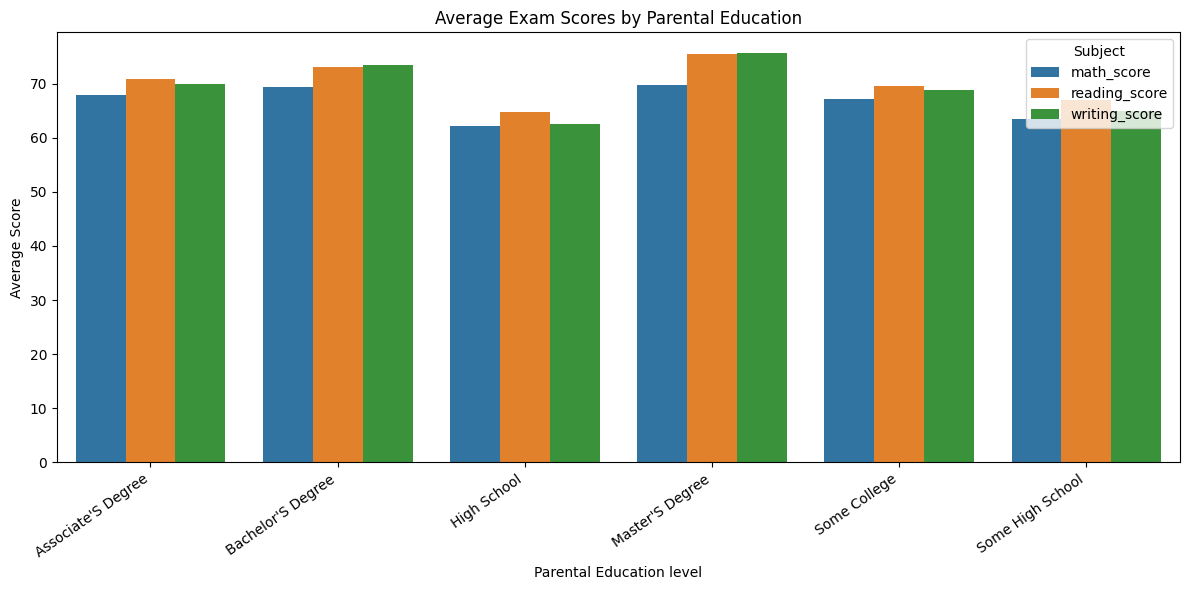

In [35]:
plt.figure(figsize=(12, 6))

parent_scores = df.groupby('parental_education')[
    ['math_score', 'reading_score', 'writing_score']
].mean().reset_index()

parent_scores_melted = parent_scores.melt(
    id_vars='parental_education',
    var_name='Subject',
    value_name='Average Score'
)

sns.barplot(
    data=parent_scores_melted,
    x='parental_education',
    y='Average Score',
    hue='Subject'
)

plt.title('Average Exam Scores by Parental Education')
plt.xlabel('Parental Education level')
plt.ylabel('Average Score')
plt.xticks(rotation=35, ha='right')
plt.legend(title='Subject')
plt.tight_layout()
plt.show()

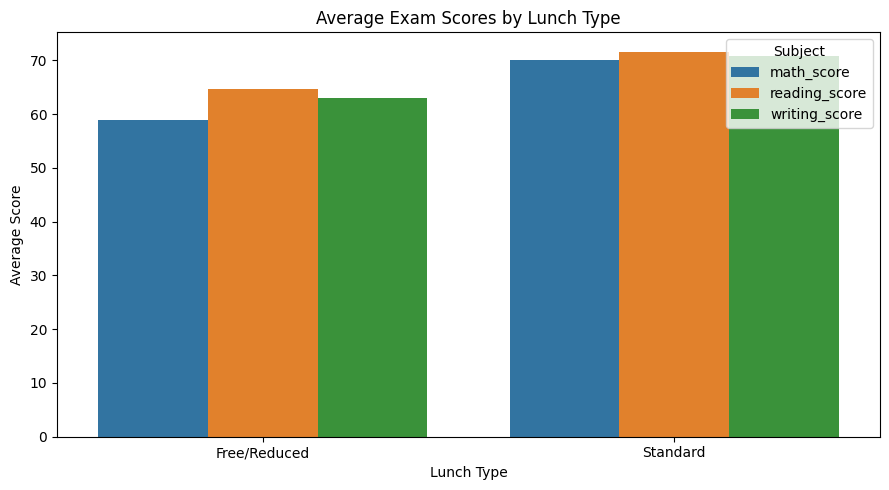

In [36]:
#Average scores by lunch type

lunch_avg = (
    df.groupby('lunch')[score_cols]
      .mean()
      .reset_index()
)

lunch_long = lunch_avg.melt(
    id_vars='lunch',
    value_vars=score_cols,
    var_name='Subject',
    value_name='Average Score'
)

plt.figure(figsize=(9, 5))

sns.barplot(
    data=lunch_long,
    x='lunch',
    y='Average Score',
    hue='Subject'
)

plt.title('Average Exam Scores by Lunch Type')
plt.xlabel('Lunch Type')
plt.ylabel('Average Score')
plt.legend(title='Subject')
plt.tight_layout()
plt.show()

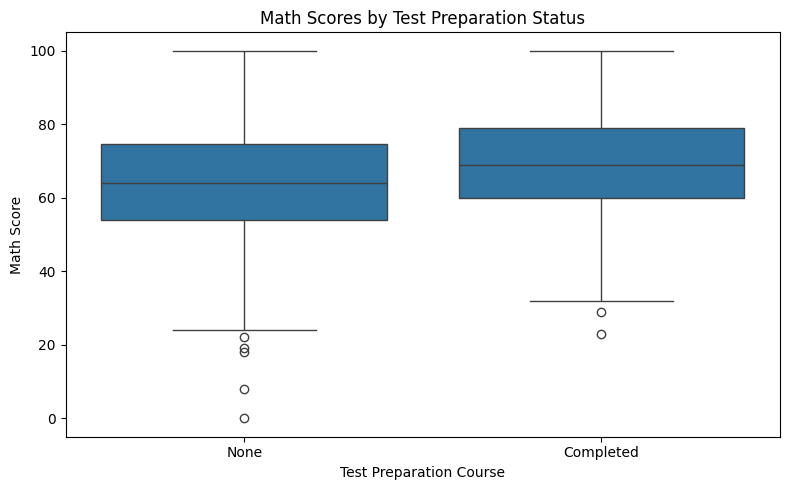

In [38]:
#Compare scores by test preparation
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x='test_prep',
    y='math_score'
)

plt.title('Math Scores by Test Preparation Status')
plt.xlabel('Test Preparation Course')
plt.ylabel('Math Score')
plt.tight_layout()
plt.show()

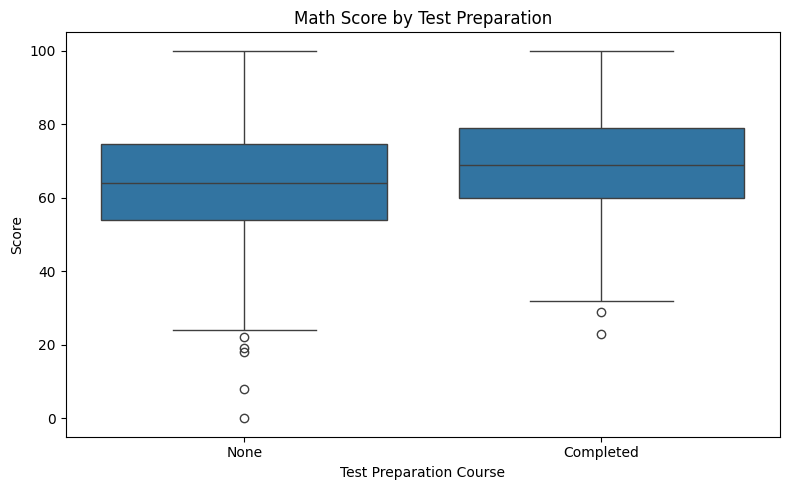

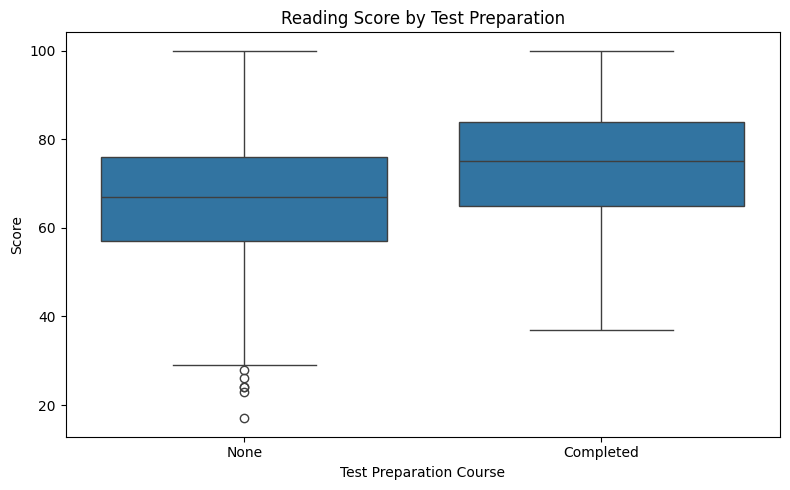

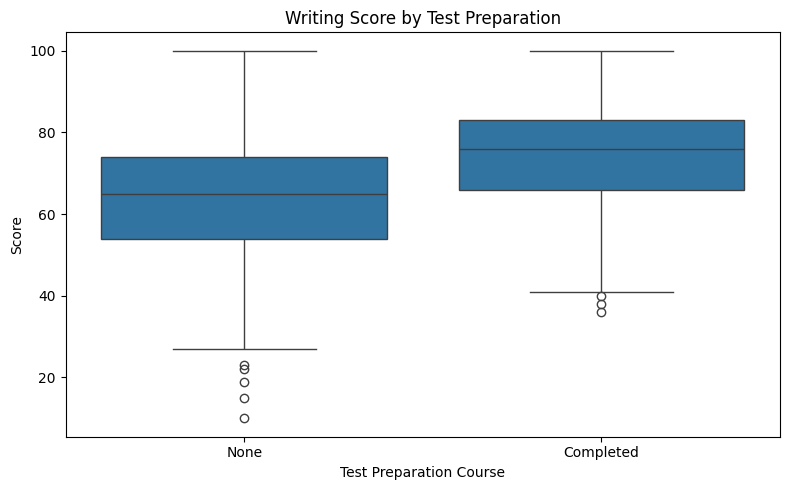

In [42]:
for subject in score_cols:
    plt.figure(figsize=(8, 5))

    sns.boxplot(
        data=df,
        x='test_prep',
        y=subject
    )

    plt.title(f"{subject.replace('_', ' ').title()} by Test Preparation")
    plt.xlabel('Test Preparation Course')
    plt.ylabel('Score')
    plt.tight_layout()
    plt.show()

In [44]:
#Compare average scores numerically
prep_summary = (
    df.groupby('test_prep')[score_cols]
      .agg(['mean', 'median', 'std', 'count'])
)

prep_summary

math_score                         reading_score                    \
                mean median        std count          mean median        std   
test_prep                                                                      
Completed  69.695531   69.0  14.444699   358     73.893855   75.0  13.638384   
None       64.077882   64.0  15.192376   642     66.534268   67.0  14.463885   

                writing_score                          
          count          mean median        std count  
test_prep                                              
Completed   358     74.418994   76.0  13.375335   358  
None        642     64.504673   65.0  14.999661   642

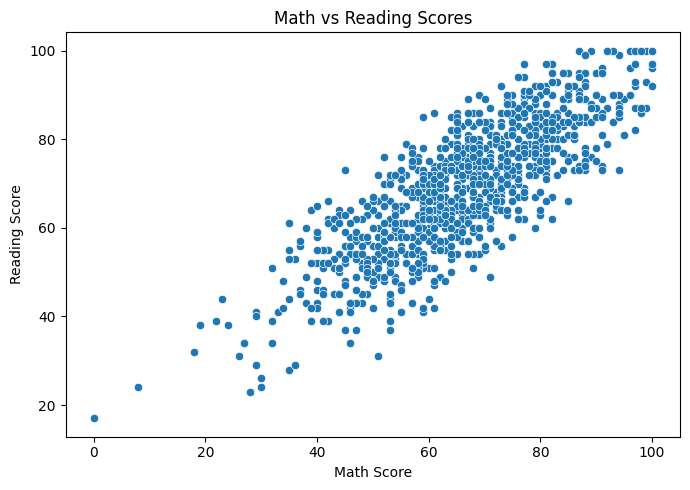

In [46]:
#Math vs Reading
plt.figure(figsize=(7,5))

sns.scatterplot(
    data=df,
    x='math_score',
    y='reading_score'
)

plt.title('Math vs Reading Scores')
plt.xlabel('Math Score')
plt.ylabel('Reading Score')
plt.tight_layout()
plt.show()

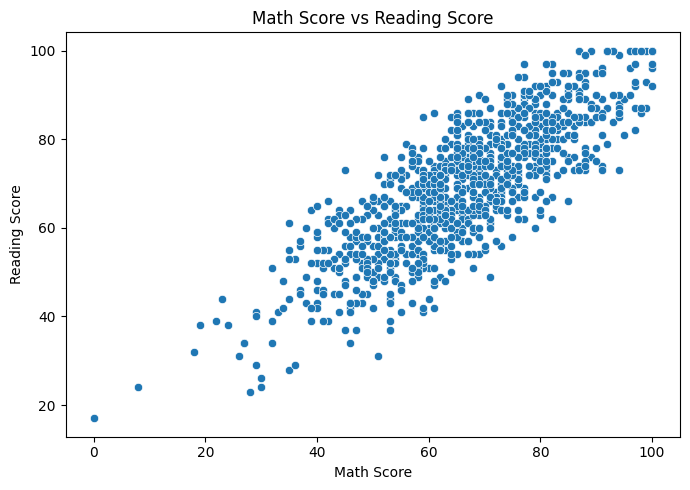

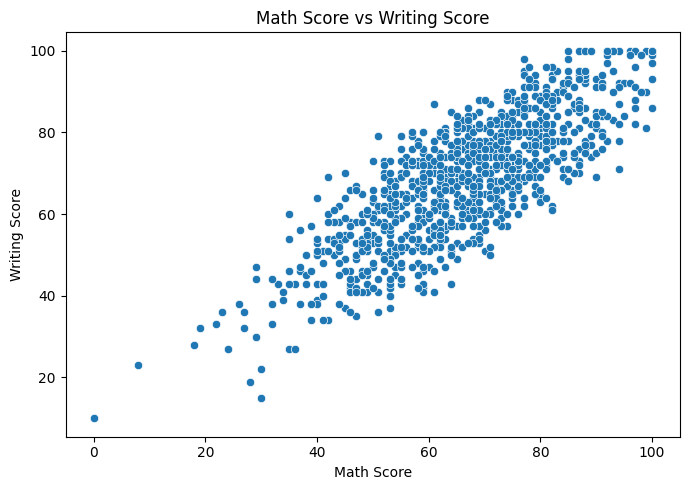

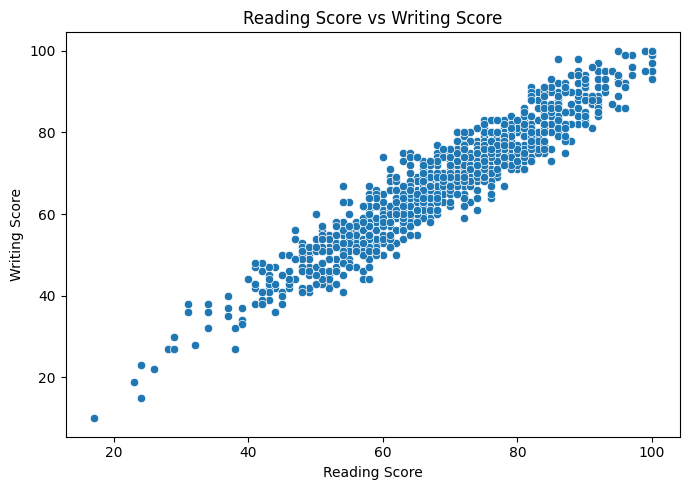

In [48]:
#Compare all subject pairs
pairs = [
    ('math_score', 'reading_score'),
    ('math_score', 'writing_score'),
    ('reading_score', 'writing_score')
]

for x_col, y_col in pairs:
    plt.figure(figsize=(7, 5))

    sns.scatterplot(
        data=df,
        x=x_col,
        y=y_col
    )

    plt.title(f"{x_col.replace('_', ' ').title()} vs {y_col.replace('_', ' ').title()}")
    plt.xlabel(x_col.replace('_', ' ').title())
    plt.ylabel(y_col.replace('_', ' ').title())

    plt.tight_layout()
    plt.show()

In [49]:
#Calculate the correlation matrix
correlation_matrix = df[score_cols].corr()

correlation_matrix

,math_score,reading_score,writing_score
math_score,1.000000,0.817580,0.802642
reading_score,0.817580,1.000000,0.954598
writing_score,0.802642,0.954598,1.000000


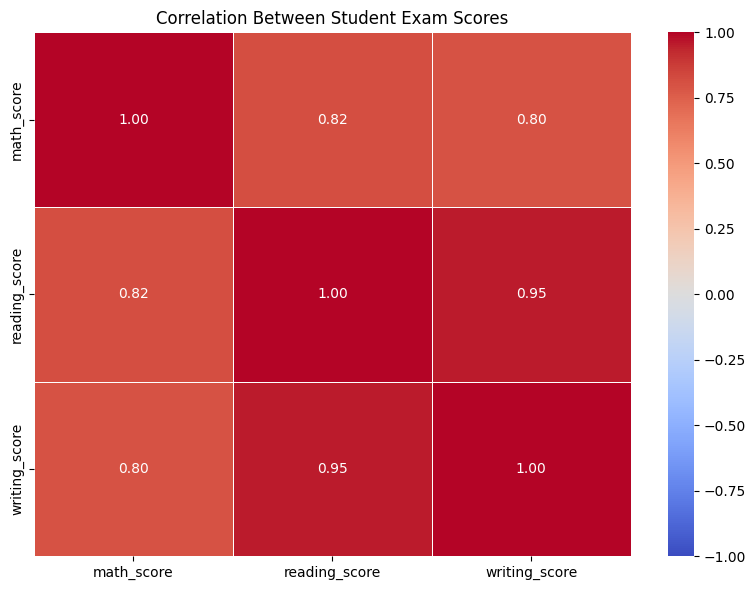

In [50]:
plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Between Student Exam Scores")
plt.tight_layout()
plt.show()